# Gridworld


Nel Reinforcement Learning (RL), un GridWorld è l'"Hello World" degli ambienti. È uno spazio discreto e bidimensionale in cui un agente si sposta da una cella all'altra per massimizzare le proprie ricompense.

È il ponte perfetto tra teoria e pratica, perché ogni componente di un Processo Decisionale di Markov (MDP) è visibile e numerabile.

Un GridWorld è definito da quattro componenti matematiche fondamentali:

- Stati (S): ogni cella della griglia (ad es. (x,y) oppure un indice appiattito da 0 a 15).

- Azioni (A): di solito quattro mosse discrete: Su, Giù, Sinistra e Destra.

- Transizioni (P): le regole di movimento. In una griglia semplice sono deterministiche (muoversi a 'Destra' porta sempre nella cella a destra). Se si urta un muro, si resta fermi.

- Ricompense (R): il segnale di feedback.

- Penalità per passo: di solito −1 per mossa, per costringere l'agente a trovare il percorso più breve.

- Obiettivo: una grande ricompensa positiva oppure 0 (con penalità altrove).

- Trappole: grandi ricompense negative (ad es. −10) che possono terminare l'episodio.

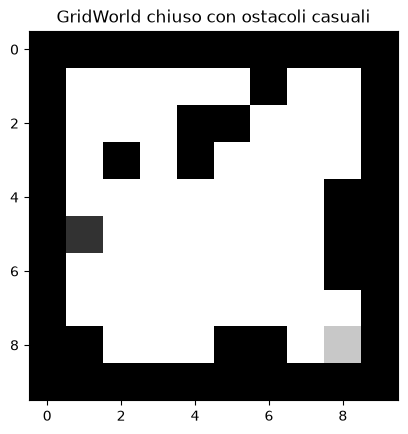

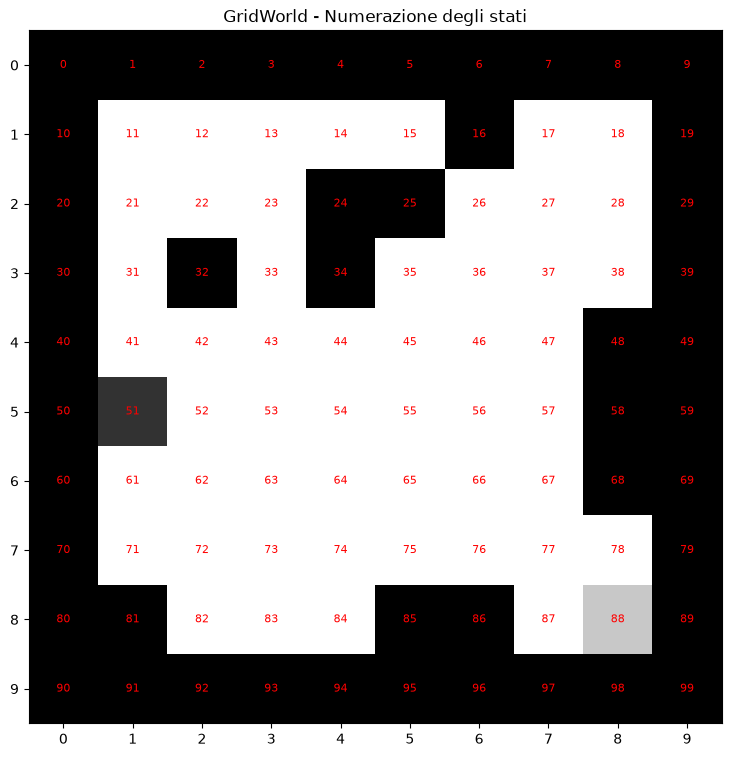

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import seaborn as sns

# Codifica dei valori della bitmap:
# 0 = muro, 50 = trappola, 200 = obiettivo, 255 = cella libero


def generate_enclosed_map(rows=30, cols=30, wall_density=0.25, trap_density=0.02):
    """Genero una griglia chiusa da muri, con muri interni e trappole casuali."""
    # 1. Parto da una griglia tutta libera (255)
    grid = np.full((rows, cols), 255, dtype=np.uint8)
    
    # 2. Metto i muri sul bordo, così l'agente non può uscire
    grid[0, :] = 0   # Muro superiore
    grid[-1, :] = 0  # Muro inferiore
    grid[:, 0] = 0   # Muro sinistro
    grid[:, -1] = 0  # Muro destro
    
    # 3. Estraggo un numero casuale in [0, 1) per ogni cella interna
    interior_shape = (rows-2, cols-2)
    random_roll = np.random.rand(*interior_shape)
    
    # 4. Creo una maschera che è True solo all'interno (bordo escluso)
    interior_mask = np.full((rows, cols), False)
    interior_mask[1:-1, 1:-1] = True
    
    # 5. Le celle con numero < wall_density diventano muri (0),
    #    quelle con numero > 1 - trap_density diventano trappole (50)
    #    (np.pad riporta la matrice interna alla dimensione completa)
    grid[(interior_mask) & (np.pad(random_roll < wall_density, 1, constant_values=False))] = 0
    grid[(interior_mask) & (np.pad(random_roll > 1 - trap_density, 1, constant_values=False))] = 50
    
    # 6. Metto l'obiettivo nell'ultima cella interna in basso a destra
    grid[-2, -2] = 200
    
    return grid

# 1. Genero una mappa 10x10 e la mostro
rows, cols = 10, 10
grid_bitmap = generate_enclosed_map(rows, cols)
plt.imshow(grid_bitmap, cmap='gray')
plt.title("GridWorld chiuso con ostacoli casuali")

# 2. Rifaccio il grafico più grande, scrivendo in ogni cella il numero dello stato
plt.figure(figsize=(9, 9))
plt.imshow(grid_bitmap, cmap='gray', vmin=0, vmax=255)

rows, cols = grid_bitmap.shape

for r in range(rows):
    for c in range(cols):
        # 3. Indice appiattito dello stato: s = riga * n_colonne + colonna
        state = r * cols + c

        plt.text(
            c, r, str(state),
            ha='center',
            va='center',
            color='red',
            fontsize=8
        )

plt.title("GridWorld - Numerazione degli stati")
plt.xticks(range(cols))
plt.yticks(range(rows))


plt.show()

In [2]:
# Definisco ricompensa ed eventuale terminazione per ogni tipo di cella
WORLD_CONFIG = {
    0:   {"reward": 0,      "terminal": False, "label": "Wall"},   # Penalità gestita dal 'restare fermi'
    50:  {"reward": -10,    "terminal": True,  "label": "Trap"},   # Grande penalità, termina il gioco
    200: {"reward": 10,     "terminal": True,  "label": "Goal"},   # Grande premio, termina il gioco
    255: {"reward": -1,     "terminal": False, "label": "Path"}    # Costo per passo per incoraggiare la velocità
}

def parse_grid(grid_bitmap):
    """Converto la bitmap in due mappe: ricompense e stati terminali."""
    rows, cols = grid_bitmap.shape
    # 1. Inizializzo la mappa delle ricompense e la maschera dei terminali
    reward_grid = np.zeros((rows, cols))
    terminal_mask = np.zeros((rows, cols), dtype=bool)

    for val, props in WORLD_CONFIG.items():
        # 2. Trovo tutte le celle della bitmap con questo valore
        mask = (grid_bitmap == val)

        # 3. Assegno a quelle celle la ricompensa e il flag terminale
        reward_grid[mask] = props["reward"]
        terminal_mask[mask] = props["terminal"]
        
    return reward_grid, terminal_mask

reward_grid, terminal_mask = parse_grid(grid_bitmap)

In [3]:
MOVEMENTS = [(-1, 0), (1, 0), (0, -1), (0,1)]
#               SU -- GIÙ -- SINISTRA -- DESTRA  

def step(s, action_idx, grid_bitmap, reward_grid, terminal_mask):
    """Eseguo un'azione dallo stato s: restituisco (s_next, reward, done)."""
    #converte l'indice s in una posizione riga, colonna e recupera le ricompense

    rows, cols = grid_bitmap.shape
    row, col = divmod(s, cols)
    
    # Definisce gli spostamenti del movimento
    dr, dc = MOVEMENTS[action_idx]
    # TODO: calcolo lo stato successivo, la ricompensa e se l'episodio è finito

    # 1. Calcolo la cella di arrivo
    new_row, new_col = row + dr, col + dc

    # 2. Se esco dalla griglia o vado contro un muro, resto fermo
    if not (0 <= new_row < rows and 0 <= new_col < cols) or grid_bitmap[new_row, new_col] == 0:
        new_row, new_col = row, col

    # 3. Riconverto (riga, colonna) nell'indice dello stato
    s_next = new_row * cols + new_col

    # 4. Leggo la ricompensa della cella di arrivo e controllo se è terminale (trappola o obiettivo)
    reward = reward_grid[new_row, new_col]
    done = terminal_mask[new_row, new_col]
    
    return s_next, reward, done

def simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, gamma=0.9, max_steps=100):
    """Simulo un episodio seguendo la policy e calcolo i ritorni scontati."""
    state = start_state
    episode_history = []
    
    for t in range(max_steps):
        # TODO: simulo un passo dell'episodio

        # 1. Scelgo l'azione con la policy
        action = policy(state)

        # 2. Eseguo l'azione nell'ambiente
        next_state, r, done = step(state, action, grid_bitmap, reward_grid, terminal_mask)

        # 3. Salvo la transizione e mi sposto nel nuovo stato
        episode_history.append((state, action, next_state, r))
        state = next_state

        # 4. Mi fermo se ho raggiunto uno stato terminale
        if done:
            break
    
    # Calcola il ritorno G_t = somma delle ricompense scontate
    G = 0
    # Calcoliamo all'indietro per efficienza: G = r + gamma * G
    transitions = []
    returns = []
    for state, action, next_state, r in reversed(episode_history):
        # TODO: aggiorno il ritorno e salvo la transizione

        # 1. Aggiorno il ritorno: G_t = r_{t+1} + gamma * G_{t+1}
        G = r + gamma * G

        # 2. Salvo il ritorno e la transizione con il suo G
        returns.append(G)
        transitions.append((state, action, next_state, r, G))

    # Rimetto le transizioni in ordine cronologico
    # (returns resta all'indietro, così returns[-1] è il ritorno G_0 dallo stato iniziale)
    transitions.reverse()
    
    # Restituisce l'ultimo ritorno e le transizioni per l'analisi
    return returns[-1], transitions

In [4]:
def random_policy(s):  # Policy casuale per i test
    """Scelgo un'azione a caso tra le 4 con probabilità uniforme (0.25 ciascuna)."""
    # TODO: restituisco un'azione casuale
    return np.random.randint(0, 4)

In [5]:
G_final, episode_history = simulate_episode(12, grid_bitmap, reward_grid, terminal_mask, random_policy, gamma=0.9, max_steps=100)

## Monte Carlo Gridworld

La Monte Carlo Policy Evaluation è un metodo model-free usato per stimare la funzione di valore di ciascuno stato, generando più episodi simulati e facendo la media dei ritorni ottenuti.

1. Si avvia un episodio dallo stato selezionato.
2. Si segue la policy data per scegliere le azioni e simulare i movimenti dell'agente.
3. Si raccoglie la sequenza di stati visitati e di ricompense finché non si raggiunge uno stato terminale o si supera il numero massimo di passi.
4. Si calcola il ritorno scontato per ogni stato visitato, considerando le ricompense ottenute da quel punto fino alla fine dell'episodio.
5. Si ripete questo processo per un numero specificato di episodi (`num_episodes`).
6. Si stima il valore di ogni stato facendo la media dei ritorni raccolti negli episodi simulati.

Il valore stimato dello stato è:

$$
V^\pi(s)\approx\frac{1}{N}\sum_{i=1}^{N}G_i(s)
$$

dove \(N\) è il numero di ritorni raccolti per lo stato \(s\), e \(G_i(s)\) è il ritorno scontato osservato dopo aver visitato quello stato durante l'episodio \(i\).

### Monte Carlo First-Visit ed Every-Visit

La Monte Carlo Policy Evaluation può essere implementata con due approcci diversi, a seconda di come vengono gestite le visite ripetute allo stesso stato all'interno di un episodio.

**First-Visit Monte Carlo** considera solo la prima occorrenza di ogni stato all'interno di un episodio. Se l'agente visita lo stesso stato più volte durante un episodio, solo il ritorno associato alla prima visita viene usato per aggiornare la stima del valore. Le visite successive a quello stato nello stesso episodio vengono ignorate.

**Every-Visit Monte Carlo**, invece, considera ogni occorrenza di uno stato all'interno di un episodio. Ogni visita genera un ritorno, e tutti questi ritorni vengono inclusi nella media usata per stimare il valore dello stato.

Entrambi gli approcci stimano la stessa funzione di valore degli stati, ma differiscono nel modo in cui i ritorni vengono raccolti e mediati.

A differenza dell'approccio analitico di Bellman, Monte Carlo non richiede di risolvere un sistema di equazioni lineari né di calcolare esplicitamente la matrice di transizione. Stima invece i valori degli stati attraverso simulazioni ripetute e medie statistiche.

Questo rende Monte Carlo particolarmente utile quando le probabilità di transizione dell'ambiente sono sconosciute, oppure quando la funzione di valore è più facile da stimare tramite esperienza simulata che tramite un modello analitico.

**SUGGERIMENTO: usa la media incrementale**

Invece di memorizzare tutti i ritorni e ricalcolarne la media dopo ogni episodio, possiamo usare la **media incrementale** per aggiornare la stima del valore dello stato online.

La regola di aggiornamento è:

$$
V_{n+1}(s)=V_n(s)+\frac{1}{N(s)}\left(G-V_n(s)\right)
$$

dove:
- $V_n(s)$ è il valore stimato corrente dello stato \(s\).
- $G$ è il nuovo ritorno osservato.
- $N(s)$ è il numero di volte in cui lo stato \(s\) è stato visitato e considerato per l'aggiornamento.

Questo approccio evita di memorizzare tutti i ritorni raccolti in precedenza, riducendo l'uso di memoria e producendo la stessa media aritmetica.
Nella nostra implementazione, l'insieme `visited_states` garantisce che ogni stato venga aggiornato una sola volta per episodio, il che corrisponde all'approccio **First-Visit Monte Carlo**.

In [6]:
def first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, policy, num_episodes=500, max_steps=100):
    """V(s) ≈ media dei ritorni G osservati alla PRIMA visita di s in ogni episodio."""
    rows, cols = grid_bitmap.shape
    V_mc = np.zeros(rows * cols)
    returns_count = np.zeros(rows * cols)  # Per contare le prime visite

    # TODO: stimo V con il Monte Carlo First-Visit
    for _ in range(num_episodes):
        # 1. Simulo un episodio e ottengo le transizioni con i loro ritorni
        _, transitions = simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, max_steps=max_steps)

        visited_states = set()
        for s, a, s_next, r, G in transitions:
            # 2. Considero solo la prima visita di ogni stato nell'episodio
            if s in visited_states:
                continue
            visited_states.add(s)

            # 3. Aggiorno il valore con la media incrementale: V <- V + (G - V) / N
            returns_count[s] += 1
            V_mc[s] += (G - V_mc[s]) / returns_count[s]
    
    return V_mc.reshape(rows, cols)

In [7]:
def every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, policy, num_episodes=500, max_steps=100):
    """V(s) ≈ media dei ritorni G osservati a OGNI visita di s in ogni episodio."""
    rows, cols = grid_bitmap.shape
    V_mc = np.zeros(rows * cols)
    returns_count = np.zeros(rows * cols)  # Per contare le visite

    for _ in range(num_episodes):
        # 1. Simulo un episodio e ottengo le transizioni con i loro ritorni
        _, transitions = simulate_episode(start_state, grid_bitmap, reward_grid, terminal_mask, policy, max_steps=max_steps)

        # 2. Considero tutte le visite, anche quelle ripetute
        for s, a, s_next, r, G in transitions:
            # 3. Aggiorno il valore con la media incrementale: V <- V + (G - V) / N
            returns_count[s] += 1
            V_mc[s] += (G - V_mc[s]) / returns_count[s]

    return V_mc.reshape(rows, cols)

In [8]:
# 1. Stato da cui partono tutti gli episodi (riga 1, colonna 2)
start_state = 12 
#V_mc_grid = monte_carlo_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=500)

# 2. Stimo V con entrambe le varianti di Monte Carlo, usando la policy casuale
V_mc_grid_fv = first_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=10000, max_steps=200)
V_mc_grid_ev = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, random_policy, num_episodes=10000, max_steps=200)

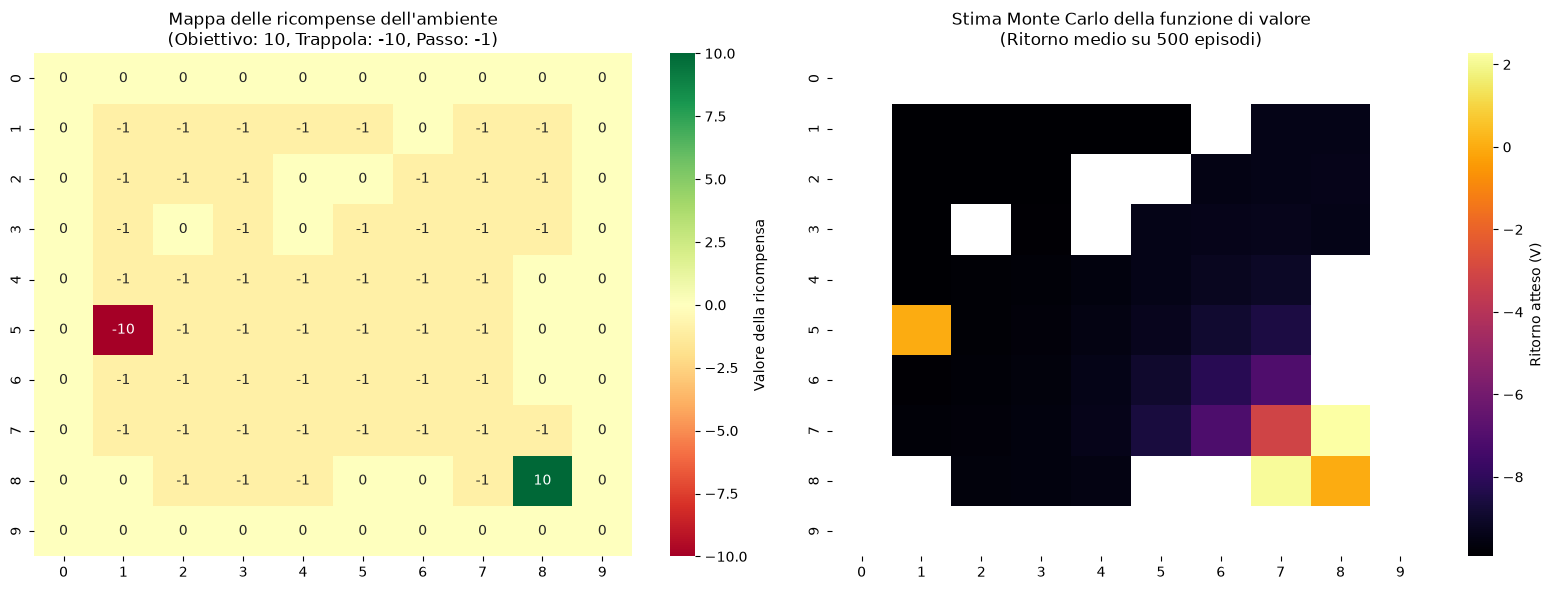

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. A sinistra: la mappa delle ricompense dell'ambiente
sns.heatmap(reward_grid, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Valore della ricompensa'})
ax[0].set_title("Mappa delle ricompense dell'ambiente\n(Obiettivo: 10, Trappola: -10, Passo: -1)")

# 2. A destra: la V stimata con Monte Carlo (Every-Visit)
#    Maschero i muri così appaiono vuoti (lì il valore è irrilevante)
mask_walls = (grid_bitmap == 0)
sns.heatmap(V_mc_grid_ev, annot=False, cmap="inferno", ax=ax[1], mask=mask_walls, cbar_kws={'label': 'Ritorno atteso (V)'})
ax[1].set_title("Stima Monte Carlo della funzione di valore\n(Ritorno medio su 500 episodi)")

plt.tight_layout()
plt.show()

## Risolvere il problema con le equazioni di Bellman

Questo è il "motore matematico" del laboratorio. Poiché usiamo una Policy Casuale Fissa, l'Equazione di Bellman passa da un complesso problema di ottimizzazione a un semplice sistema di equazioni lineari.1. L'Equazione di Bellman per l'aspettazionePer una policy fissata $\pi$, il valore di uno stato $s$ è la somma attesa delle ricompense future scontate. Matematicamente si esprime come:$$V^{\pi}(s) = \sum_{a \in A} \pi(a|s) \sum_{s' \in S, r \in R} p(s', r|s, a) \left[ r + \gamma V^{\pi}(s') \right]$$


Poiché usiamo una Policy Casuale Uniforme ($\pi(a|s) = 0.25$) e l'ambiente è Deterministico ($p=1$ per il risultato di un'azione), l'equazione si semplifica in:$$V(s) = 0.25 \sum_{a \in \{U,D,L,R\}} \left( \text{Reward}(s, a) + \gamma V(s_{next}) \right)$$


Per risolverla per tutti gli $N$ stati contemporaneamente, la riscriviamo in forma matrice-vettore. Questo trasforma $16$ (o $100$) equazioni individuali in un'unica operazione:$$\mathbf{V} = \mathbf{R} + \gamma \mathbf{P} \mathbf{V}$$


Dove:

- $\mathbf{V}$: un vettore $N \times 1$ dei valori che vogliamo trovare.

- $\mathbf{R}$: un vettore $N \times 1$ delle ricompense attese per ogni stato sotto la policy casuale.

- $\mathbf{P}$: una Matrice di Probabilità di Transizione $N \times N$, dove $P_{ij}$ è la probabilità di arrivare nello stato $j$ partendo dallo stato $i$.

- $\gamma$: il fattore di sconto (ad es. $0.9$).

P codifica la nostra policy: in questo caso è una matrice che ha entrate 0 per ogni elemento non raggiungibile e la probabilità data dalla policy per gli altri! Seconda nota: possiamo raccogliere una "ricompensa attesa", dato che da lì possiamo ciclare su tutti gli stati e raccogliere questo vettore R (che risulta dalla moltiplicazione $PR^*$, dove $R^*$ contiene tutte le ricompense)

Per trovare $\mathbf{V}$, riorganizziamo l'equazione con l'algebra lineare:Portiamo i termini in $V$ da un lato: $$ \mathbf{V} - \gamma \mathbf{P} \mathbf{V} = \mathbf{R}$$ Raccogliamo $\mathbf{V}$: $$(\mathbf{I} - \gamma \mathbf{P}) \mathbf{V} = \mathbf{R}$$ Risolviamo per $\mathbf{V}$: $$\mathbf{V} = (\mathbf{I} - \gamma \mathbf{P})^{-1} \mathbf{R} $$



### La matrice di transizione P e il vettore delle ricompense attese R

La matrice di transizione **P** codifica sia la dinamica dell'ambiente sia la nostra policy casuale fissata.

Poiché usiamo una Policy Casuale Uniforme, ogni azione ha probabilità 0.25. Quindi ogni elemento \(P_{ij}\) rappresenta la probabilità di passare dallo stato \(i\) allo stato \(j\), tenendo conto di tutte le azioni possibili:

$$
P_{ij}=\sum_a \pi(a|s_i)P(s_j|s_i,a)
$$

Poiché l'ambiente è deterministico, ogni azione porta esattamente a un solo stato successivo. Di conseguenza, \(P_{ij}\) vale 0.25 per ogni azione che porta nello stato \(j\), e 0 se nessuna azione porta in quello stato. Se più azioni portano nello stesso stato (ad esempio quando l'agente urta un muro), le loro probabilità si sommano.

Il vettore delle ricompense attese **R** contiene la ricompensa immediata media ottenuta da ogni stato sotto la nostra policy:

$$
R_i=\sum_a\pi(a|s_i)Reward(s_i,a)
$$

Quindi possiamo calcolare la ricompensa attesa di ogni stato facendo la media delle ricompense associate alle sue quattro azioni possibili.

Infine, l'equazione di Bellman diventa:

$$
\mathbf V=\mathbf R+\gamma\mathbf P\mathbf V
$$

e può essere risolta direttamente con l'algebra lineare:

$$
\boxed{\mathbf V=(\mathbf I-\gamma\mathbf P)^{-1}\mathbf R}
$$

In [10]:
def build_matrices_from_random_policy(grid_bitmap, reward_grid, terminal_mask, gamma=0.9):
    """Costruisco P (N x N) e R (N) per la policy casuale uniforme."""
    rows, cols = grid_bitmap.shape
    num_states = rows * cols

    # Inizializza P come matrice N x N e R come vettore N x 1
    P = np.zeros((num_states, num_states))
    R_vec = np.zeros(num_states)

    for s in range(num_states):
        r, c = divmod(s, cols)
        
        # In un MDP, gli stati terminali transitano su sé stessi con prob 1.0
        if terminal_mask[r, c] or grid_bitmap[r, c] == 0: # è un muro o uno stato terminale
            P[s, s] = 1.0
            continue
            
        # 1. Policy casuale uniforme: pi(a|s) = 1/4 per ogni azione
        prob_per_action = 1 / 4
        for a_idx in range(4):
            # 2. Uso step per trovare dove porta l'azione e con quale ricompensa
            # dr, dc = [(-1,0), (1,0), (0,-1), (0,1)][a_idx]
            s_next, reward, done = step(s, a_idx, grid_bitmap, reward_grid, terminal_mask)
            
            # 3. Aggiorno la matrice di transizione P[from_state, to_state]
            #    (uso += perché azioni diverse possono portare allo stesso stato, es. contro i muri)
            P[s, s_next] += prob_per_action
            
            # 4. Aggiorno la ricompensa attesa: R(s) = sum_a pi(a|s) * Reward(s, a)
            R_vec[s] += prob_per_action * reward

    return P, R_vec


def solve_bellman_analytical(P, R_vec, gamma=0.9):
    """
    Risolve (I - gamma*P)V = R
    """
    num_states = P.shape[0]
    I = np.eye(num_states)
    
    # Risolve il sistema lineare Ax = b 
    # dove A = (I - gamma*P) e b = R_vec

    # 1. Costruisco la matrice del sistema
    A = I - gamma * P

    # 2. Risolvo con np.linalg.solve (più stabile e veloce che calcolare l'inversa)
    V_exact = np.linalg.solve(A, R_vec)
    
    return V_exact

In [11]:
# 1. Costruisco la matrice di transizione P e il vettore delle ricompense attese R
P, R_vec = build_matrices_from_random_policy(grid_bitmap, reward_grid, terminal_mask)

# 2. Risolvo il sistema di Bellman per ottenere la V esatta
V_exact = solve_bellman_analytical(P, R_vec, gamma=0.9)

# 3. Riporto i vettori alla forma della griglia per poterli disegnare
V_exact_grid = V_exact.reshape(rows, cols)

R_expected_grid = R_vec.reshape(rows, cols)

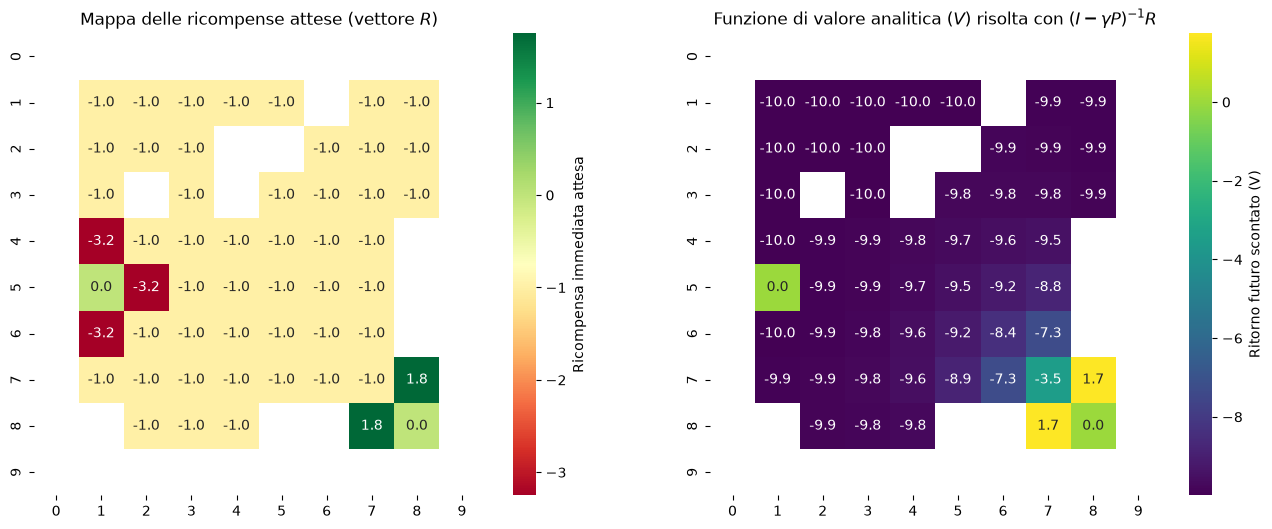

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. Definisco la maschera dei muri (non li disegno)
wall_mask = (grid_bitmap == 0)

# --- Grafico 1: Ricompense attese (R_vec) ---
# 2. Ricompensa immediata attesa in ogni stato sotto la policy casuale
sns.heatmap(R_expected_grid, mask=wall_mask, annot=True, fmt=".1f", 
            cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Ricompensa immediata attesa'})
ax[0].set_title(r"Mappa delle ricompense attese (vettore $R$)")

# --- Grafico 2: Funzione di valore esatta (V) ---
# 3. Valore esatto di ogni stato ottenuto risolvendo il sistema lineare
sns.heatmap(V_exact_grid, mask=wall_mask, annot=True, fmt=".1f",
            cmap="viridis", ax=ax[1], cbar_kws={'label': 'Ritorno futuro scontato (V)'})
ax[1].set_title(r"Funzione di valore analitica ($V$) risolta con $(I - \gamma P)^{-1} R$")

plt.show()

## Estrazione della policy

Ora da questa V possiamo estrarre una policy greedy!

Per ogni stato possiamo usare come policy lo spostamento verso lo stato che massimizza la ricompensa.

Poi rifacciamo il passo Monte Carlo e vediamo cosa succede alla funzione di valore.

In [13]:
def extract_greedy(V, grid_bitmap, terminal_mask):
    """Per ogni stato scelgo l'azione che porta nella cella vicina con V più alta."""
    nrows = V.shape[0]
    ncols = V.shape[1]

    # 1. Inizializzo la policy a -1 (nessuna azione) per tutti gli stati
    policy_vals = np.zeros(nrows * ncols, dtype=np.int32) - 1 
    for i in range(nrows):
        for j in range(ncols):
            idx = i*ncols + j

            # 2. Salto muri e stati terminali: lì non serve un'azione
            if grid_bitmap[i, j] == 0 or terminal_mask[i, j]:
                continue

            # 3. Leggo il valore dei 4 vicini; se il vicino è un muro o una trappola
            #    gli do -inf così non verrà mai scelto
            up_val = V[i - 1, j] if (grid_bitmap[i - 1, j] != 0 and grid_bitmap[i - 1, j] != 50) else -np.inf

            down_val = V[i + 1, j] if (grid_bitmap[i + 1, j] != 0 and grid_bitmap[i + 1, j] != 50) else -np.inf

            left_val = V[i, j - 1] if (grid_bitmap[i, j - 1] != 0 and grid_bitmap[i, j - 1] != 50) else -np.inf

            right_val = V[i, j + 1] if (grid_bitmap[i, j + 1] != 0 and grid_bitmap[i, j + 1] != 50) else -np.inf

            # 4. Scelgo l'azione con valore massimo (0=SU, 1=GIÙ, 2=SINISTRA, 3=DESTRA)
            policy_vals[idx] = np.argmax([up_val, down_val, left_val, right_val])


    return policy_vals

# Estraggo la policy greedy dalla V esatta calcolata con Bellman
policy_vals = extract_greedy(V_exact.reshape(grid_bitmap.shape), grid_bitmap, terminal_mask)

Ora applichiamo questa policy al Monte Carlo

In [14]:
def greedy_policy(s):
    """Restituisco l'azione greedy precalcolata per lo stato s."""
    return policy_vals[s]

# Rivaluto con Monte Carlo usando la policy greedy al posto di quella casuale
V_mc_greedy = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, greedy_policy, num_episodes=500)

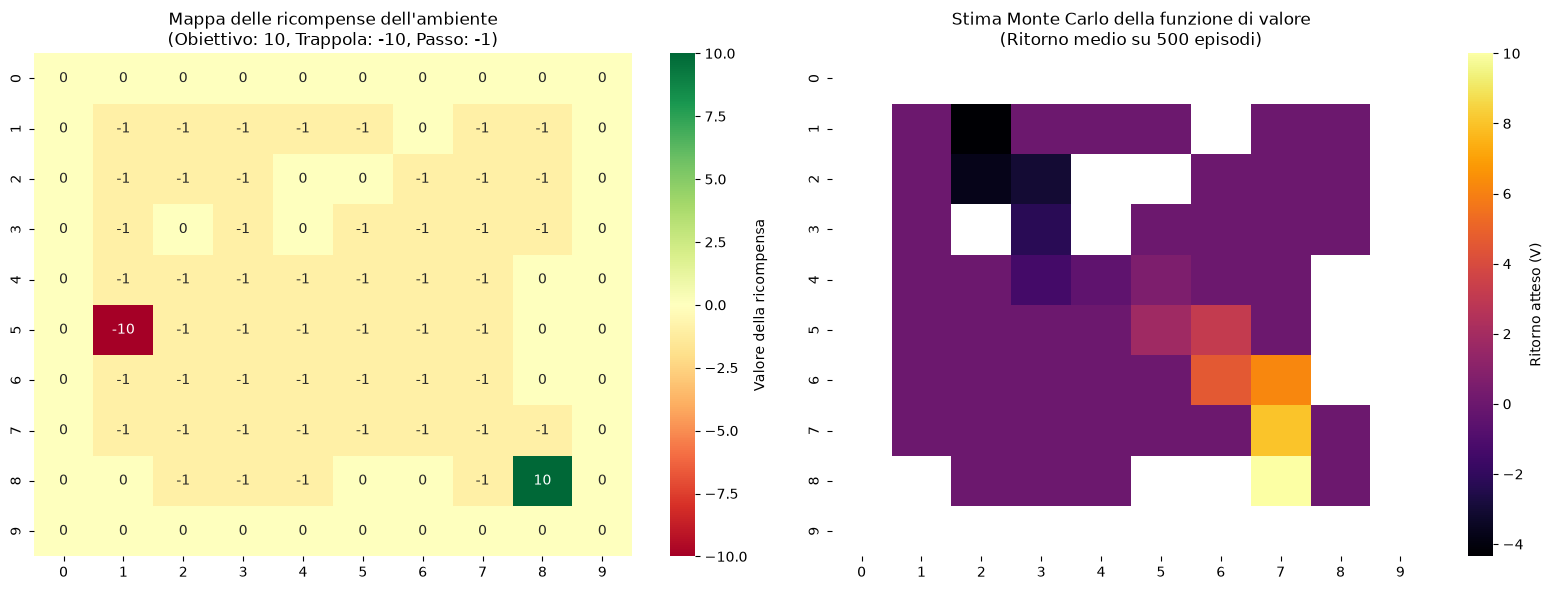

In [15]:
# visualizzo i risultati della policy greedy

fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# 1. A sinistra: la mappa delle ricompense dell'ambiente
sns.heatmap(reward_grid, annot=True, fmt=".0f", cmap="RdYlGn", ax=ax[0], cbar_kws={'label': 'Valore della ricompensa'})
ax[0].set_title("Mappa delle ricompense dell'ambiente\n(Obiettivo: 10, Trappola: -10, Passo: -1)")

# 2. A destra: la V stimata con Monte Carlo seguendo la policy greedy
#    Maschero i muri così appaiono vuoti (lì il valore è irrilevante)
mask_walls = (grid_bitmap == 0)
sns.heatmap(V_mc_greedy, annot=False, cmap="inferno", ax=ax[1], mask=mask_walls, cbar_kws={'label': 'Ritorno atteso (V)'})
ax[1].set_title("Stima Monte Carlo della funzione di valore\n(Ritorno medio su 500 episodi)")

plt.tight_layout()
plt.show()

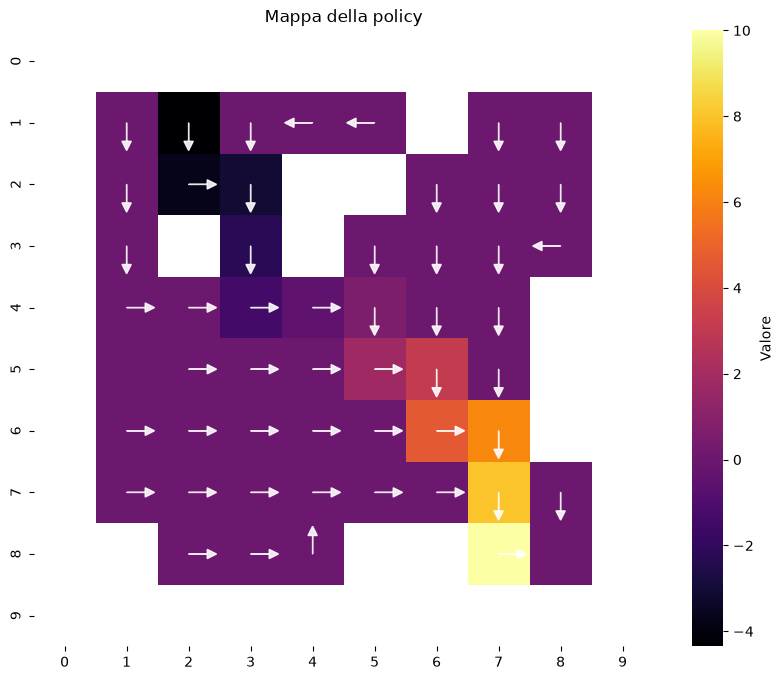

In [16]:
def plot_policy_from_func(V_grid, grid_bitmap, policy_func, title="Mappa della policy"):
    """Disegno la heatmap di V e sopra una freccia con l'azione scelta dalla policy in ogni stato."""
    nrows, ncols = grid_bitmap.shape
    plt.figure(figsize=(10, 8))
    
    # 1. Heatmap di sfondo con i valori V (muri mascherati)
    mask_walls = (grid_bitmap == 0)
    sns.heatmap(V_grid, annot=False, cmap='inferno', mask=mask_walls, cbar_kws={'label': 'Valore'})
    
    # 2. Spostamento (dx, dy) della freccia per ogni azione: 0=SU, 1=GIÙ, 2=SINISTRA, 3=DESTRA
    arrows = {0: (0, -0.3), 1: (0, 0.3), 2: (-0.3, 0), 3: (0.3, 0)}
    
    for i in range(nrows):
        for j in range(ncols):
            s = i * ncols + j
            
            # 3. Non disegno frecce su muri, trappole e obiettivo
            if grid_bitmap[i, j] in [0, 50, 200]:
                continue
                
            # 4. Chiedo alla policy quale azione sceglie in questo stato
            action = policy_func(s)
            
            # 5. Disegno la freccia partendo dal centro della cella (+0.5)
            dx, dy = arrows[action]
            plt.arrow(j + 0.5, i + 0.5, dx, dy, 
                      head_width=0.15, head_length=0.15, 
                      fc='white', ec='white', alpha=0.9)

    plt.title(title)
    plt.show()

plot_policy_from_func(V_mc_greedy, grid_bitmap, greedy_policy)

Nota che possiamo scrivere una forma semplificata dell'equazione di Bellman anche in questo caso, poiché la policy non è casuale ma deterministica.

Un esercizio aggiuntivo è ricavare la funzione di valore esatta anche in questo caso usando l'equazione di Bellman.

In [17]:
def epsilon_greedy_policy(s, epsilon=0.1):
    """Con probabilità epsilon esploro (azione casuale), altrimenti sfrutto (azione greedy)."""
    # 1. Estraggo un numero casuale e lo confronto con epsilon
    if np.random.rand() < epsilon:
        return np.random.randint(0, 4)  # Esploro: azione casuale
    else:
        return policy_vals[s]  # Sfrutto: azione greedy

## Una sorta di policy iteration

Guarda come la policy migliora partendo da una casuale

  0%|          | 0/10 [00:00<?, ?it/s]

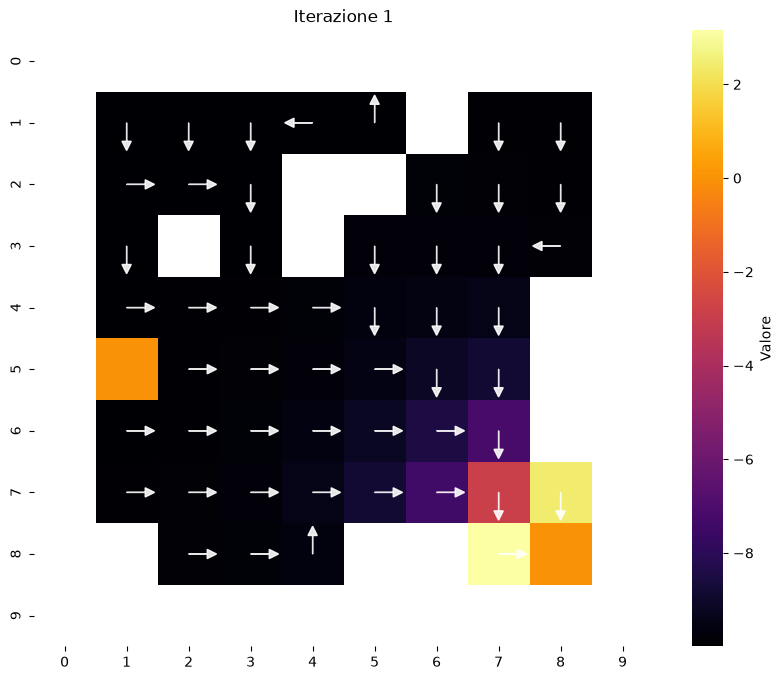

 10%|█         | 1/10 [00:01<00:16,  1.87s/it]

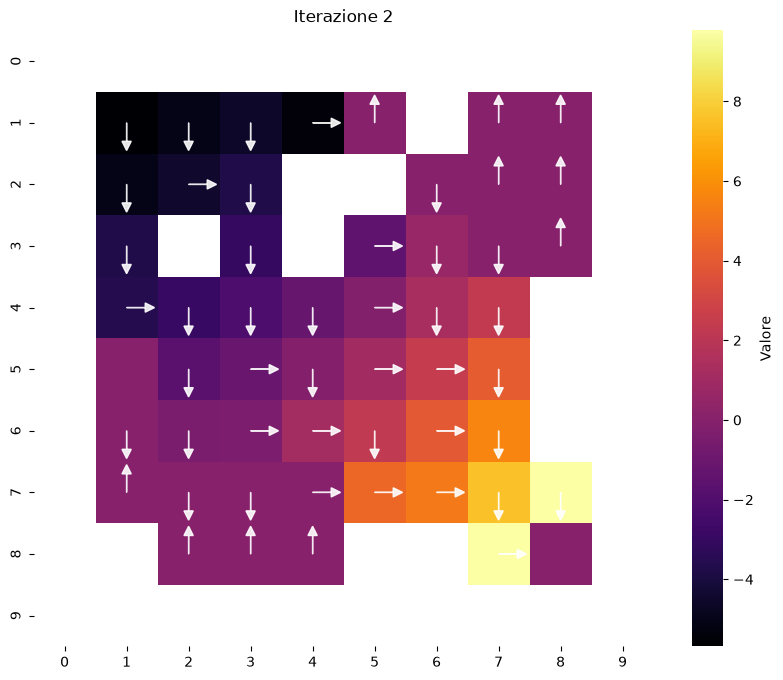

 20%|██        | 2/10 [00:02<00:11,  1.40s/it]

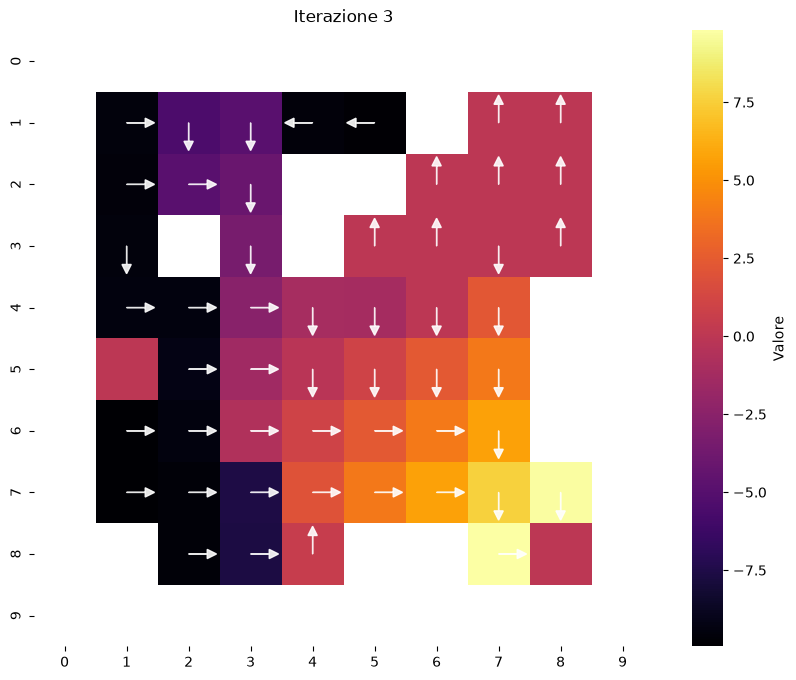

 30%|███       | 3/10 [00:04<00:09,  1.41s/it]

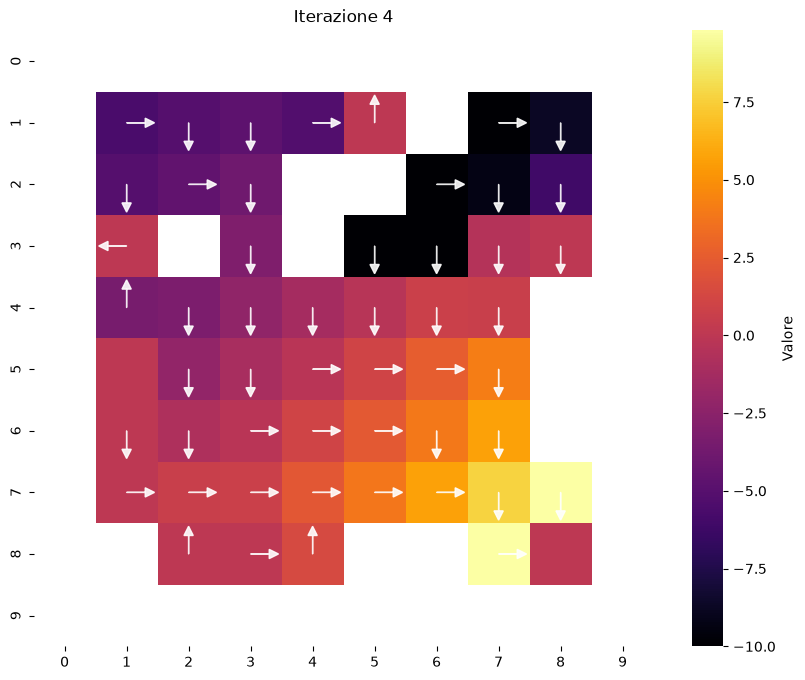

 40%|████      | 4/10 [00:05<00:08,  1.45s/it]

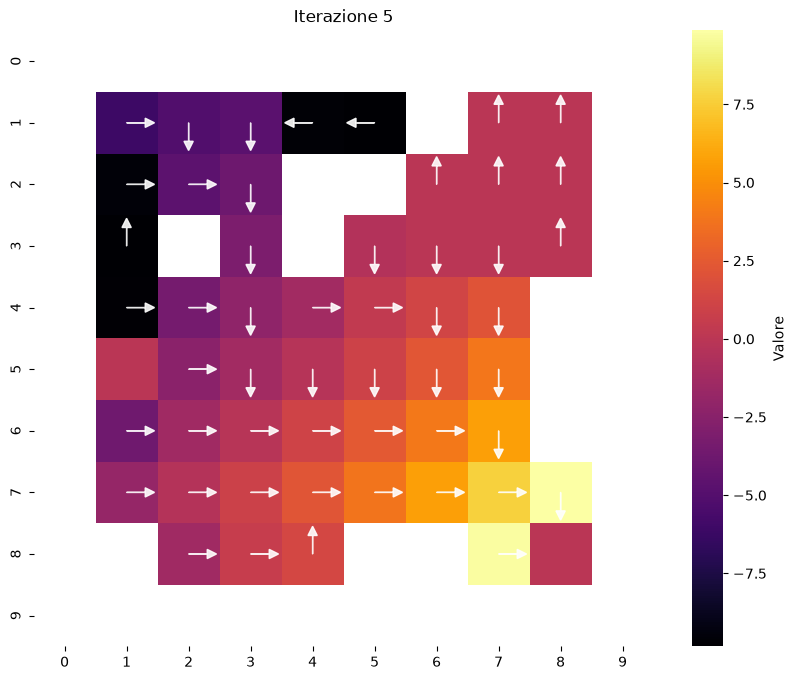

 50%|█████     | 5/10 [00:07<00:07,  1.43s/it]

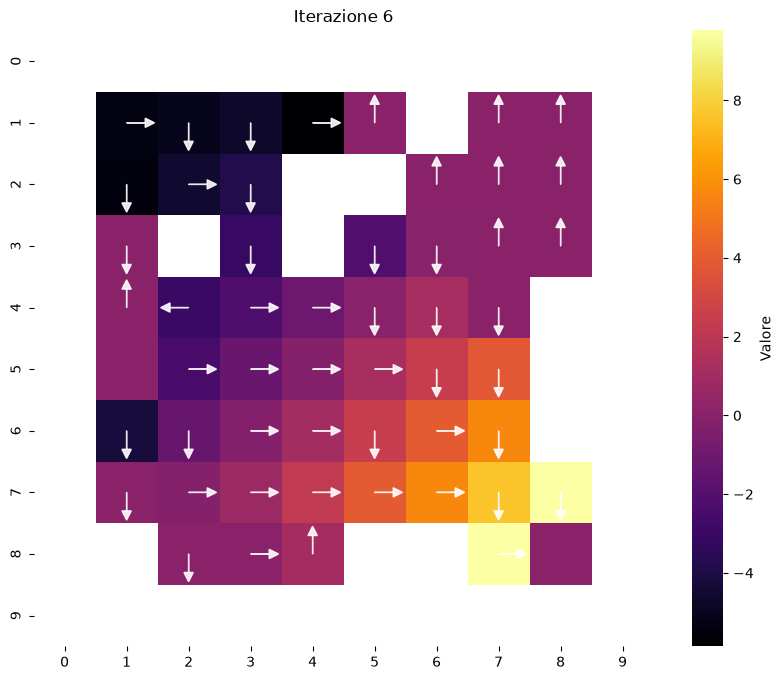

 60%|██████    | 6/10 [00:08<00:05,  1.31s/it]

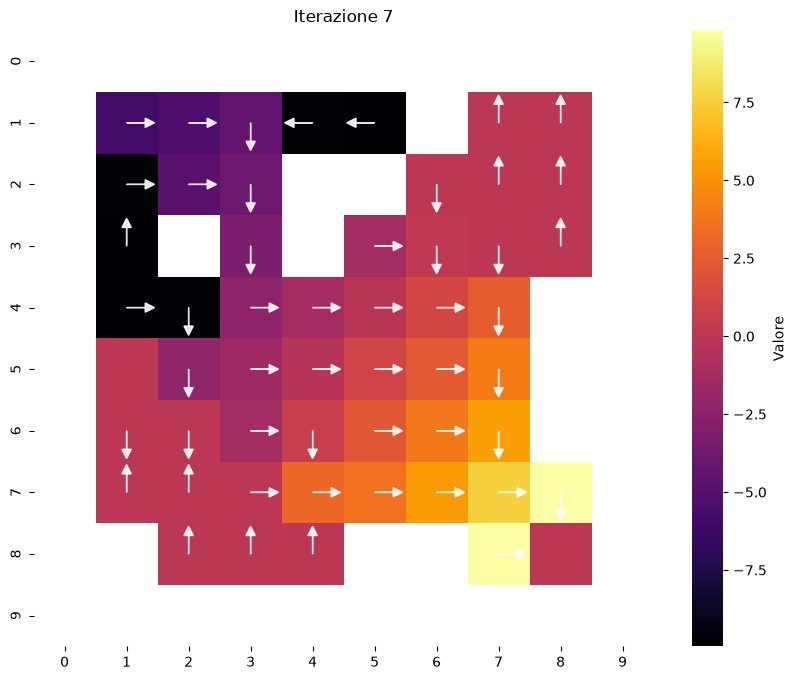

 70%|███████   | 7/10 [00:09<00:03,  1.33s/it]

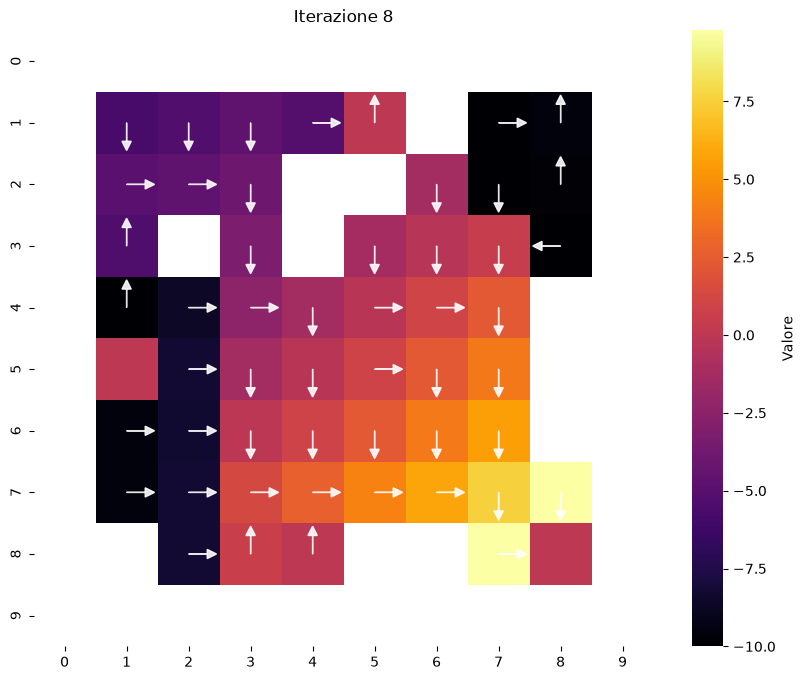

 80%|████████  | 8/10 [00:11<00:02,  1.38s/it]

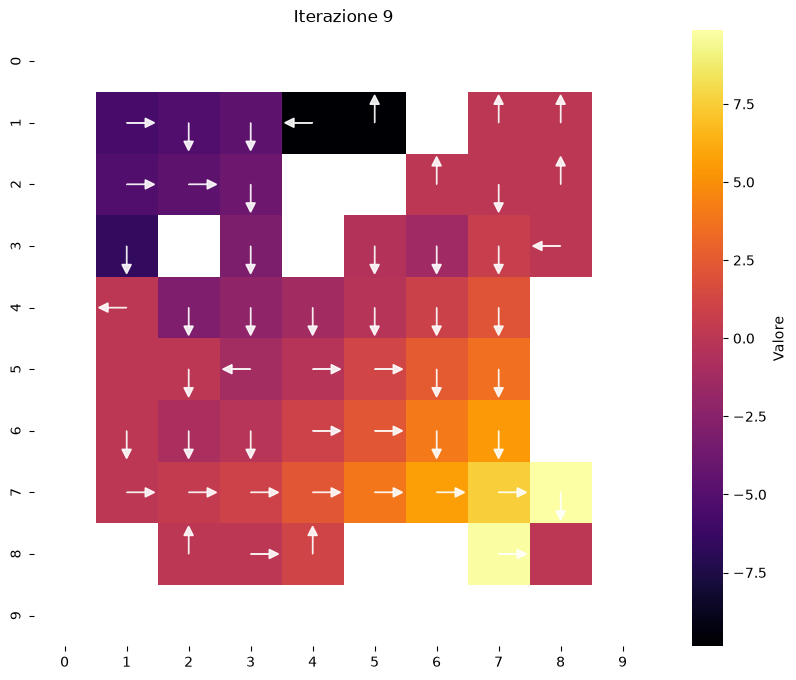

 90%|█████████ | 9/10 [00:12<00:01,  1.37s/it]

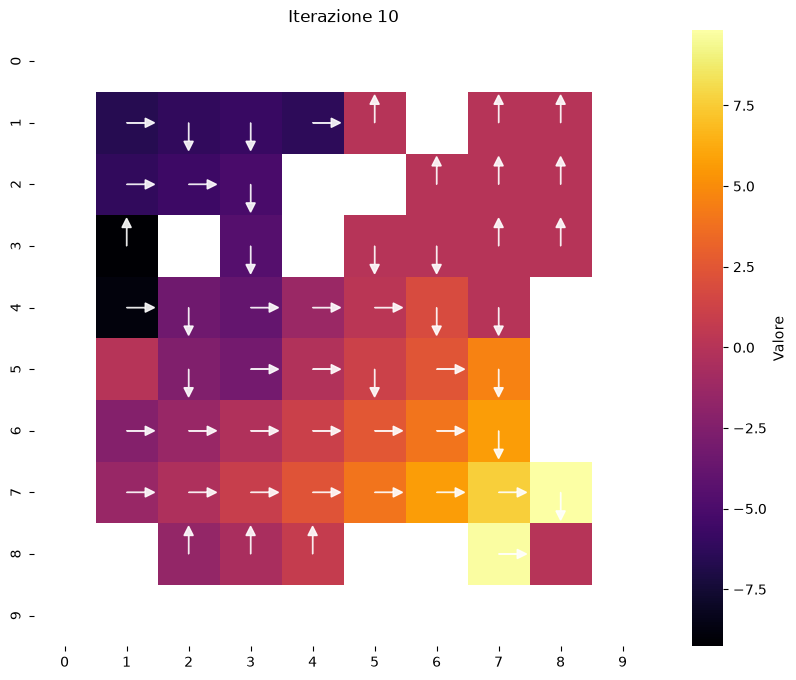

100%|██████████| 10/10 [00:13<00:00,  1.40s/it]


In [18]:
# Parto da una policy casuale e la miglioro ripetendo:
# valutazione con Monte Carlo -> estrazione della greedy -> nuova policy epsilon-greedy

def greedy_policy_to_improve(s):
    """Policy di partenza: azione casuale."""
    return np.random.randint(0, 4)

def extract_greedy_lookahead(V, grid_bitmap, reward_grid, terminal_mask, gamma=0.9):
    """Per ogni stato scelgo l'azione che massimizza r + gamma * V(s'), guardando un passo avanti."""
    nrows, ncols = V.shape
    policy = np.zeros(nrows * ncols, dtype=np.int32) - 1

    for s in range(nrows * ncols):
        i, j = divmod(s, ncols)

        # 1. Salto muri e stati terminali: lì non serve un'azione
        if grid_bitmap[i, j] == 0 or terminal_mask[i, j]:
            continue

        # 2. Per ogni azione calcolo ricompensa immediata + valore scontato dello stato di arrivo
        #    (se lo stato di arrivo è terminale, dopo non c'è più niente: conta solo r)
        q_values = []
        for a_idx in range(4):
            s_next, reward, done = step(s, a_idx, grid_bitmap, reward_grid, terminal_mask)
            q_values.append(reward + gamma * V.flat[s_next] * (not done))

        # 3. Scelgo l'azione migliore
        policy[s] = np.argmax(q_values)

    return policy

# 1. Parto dalla policy casuale
current_policy = greedy_policy_to_improve

for it in tqdm(range(10)):
    # 2. Valuto la policy corrente con Monte Carlo
    V_mc_grid = every_visit_mc_evaluation(start_state, grid_bitmap, reward_grid, terminal_mask, current_policy, num_episodes=2000, max_steps=500)

    # 3. Estraggo la policy greedy rispetto alla nuova V
    policy_vals_to_improve = extract_greedy_lookahead(V_mc_grid, grid_bitmap, reward_grid, terminal_mask)

    # 4. La nuova policy è la epsilon-greedy di quella appena estratta
    #    (l'epsilon serve a continuare a esplorare stati che Monte Carlo non ha ancora visitato)
    def epsilon_greedy_policy(s, epsilon=0.1):
        if np.random.rand() < epsilon:
            return np.random.randint(0, 4)  # Esploro: azione casuale
        else:
            return policy_vals_to_improve[s]  # Sfrutto: azione greedy

    # 5. Aggiorno la policy per il giro successivo
    current_policy = epsilon_greedy_policy

    # 6. Disegno le frecce della policy greedy sopra la V stimata
    plot_policy_from_func(V_mc_grid, grid_bitmap, lambda s: policy_vals_to_improve[s], title=f"Iterazione {it + 1}")